In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt

from pathlib import Path

from das_tools.utils import proj_path
from das_tools.processing import pisces25

plt.rcParams.update({
    "font.size": 24,          # base size
    "axes.titlesize": 24,
    "axes.labelsize": 24,
    "xtick.labelsize": 20,
    "ytick.labelsize": 20,
    "legend.fontsize": 20,
})
mpl.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "text.latex.preamble": r"\usepackage{amsmath}\usepackage{amssymb}\usepackage{times}",
})

PROJECT_ROOT = proj_path.find_project_root()

WIND_FILE = PROJECT_ROOT / "data" / "PISCES_25" / "SWIFT19_telemetry.nc"

OUT = proj_path.output_dir("bf_inv_disp")
OUT_POS = OUT / "posterior"
PREFIX = "omni_skip2_coh"
BAND = "0.10-1.00"          # frequency-window directory the posterior was scored over
CMAP = "Greys"

OUT_POS_CUR = OUT_POS / f"{PREFIX}_f{BAND}Hz_llnone"
NPZ_PATH = OUT_POS_CUR / "posterior_timeseries.npz" 


# ---- p(E, P): theta AND time marginalized ----
# posterior_timeseries.npz keeps only per-block summaries of E and P (MAP, mean,
# percentiles), not the joint grid, so the 2D posterior comes from the stacked
# file phase 2 of scripts/bf_inv_disp/analyze_bf_disp_posterior.py writes. This
# copy is the same run: its block list is checked against NPZ_PATH below.
STACK_NPZ_PATH = OUT_POS_CUR / "posterior_stacked_EP.npz" 

# "post_EP_mean_ll" = softmax(LL_sum / n_blocks), one block's worth of information;
# "post_EP" = softmax(LL_sum), the literal sum over blocks, which is ~one cell wide.
EP_FIELD = "post_EP_mean_ll"
ZOOM = True                 # crop p(E, P) to where the mass is

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

# Marginal posteriors of $(E, P)$ and of the azimuth $\theta$

**(1)** $p(E, P)$ with frequency, azimuth and time all integrated out. Per block,
$\mathrm{LL}_{EP} = \log \tfrac{1}{n_\theta}\sum_\theta e^{\mathrm{LL}(E, P, \theta)}$;
across blocks the log-likelihoods add, and $p(E, P) = \mathrm{softmax}$ of the sum
(or of the sum over $n_\mathrm{blocks}$, see `EP_FIELD`).

**(2)** $p(\theta)$ with $E$, $P$ and time integrated out. Each block's `p_theta` is
already marginalized over $(E, P)$; time is then integrated out with a uniform prior
over blocks, $p(\theta) = \tfrac{1}{N}\sum_t p(\theta\,|\,t)$. Direction changes with
the wind, so the blocks are *mixed*, not multiplied as if they shared one $\theta$.

In [2]:
ts = np.load(NPZ_PATH)
st = np.load(STACK_NPZ_PATH)

# Guard against pairing a stack from a different run / band with this timeseries.
t_ts = pd.to_datetime(ts["block_start"], unit="us").sort_values()
t_st = pd.to_datetime(st["block_starts"]).sort_values()

## 1. $p(E, P)$, marginalized over azimuth and time

**MAP** is the joint argmax over the grid, so it is always a grid node. **MMSE** is
the posterior mean $\big(\sum p\,E,\ \sum p\,P\big)$ of the same joint. Both temperings
share the MAP by construction; only the MMSE and the spread differ.

In [3]:
E_all, C_all, valid = st["E_all"], st["C_all"], st["valid"]
E_gpa, P_mpa = E_all / 1e9, C_all / 1e6


def ep_estimates(post):
    """Joint MAP and MMSE of (E, P) [Pa] from an (nE, nP) posterior."""
    post = np.where(valid, post, 0.0)
    post = post / post.sum()
    i_e, i_p = np.unravel_index(int(np.argmax(post)), post.shape)
    E_mmse = float(np.sum(post * E_all[:, None]))
    P_mmse = float(np.sum(post * C_all[None, :]))
    return dict(E_map=float(E_all[i_e]), P_map=float(C_all[i_p]),
                E_mmse=E_mmse, P_mmse=P_mmse, p_map=float(post[i_e, i_p]))


for field, name in [("post_EP", "literal, softmax(LL_sum)"),
                    ("post_EP_mean_ll", "tempered, softmax(LL_sum / n_blocks)")]:
    est = ep_estimates(st[field])
    print(f"{name}")
    print(f"  MAP  : E = {est['E_map'] / 1e9:6.3f} GPa   P = {est['P_map'] / 1e6:6.4f} MPa"
          f"   (p = {est['p_map']:.4f})")
    print(f"  MMSE : E = {est['E_mmse'] / 1e9:6.3f} GPa   P = {est['P_mmse'] / 1e6:6.4f} MPa")

post = np.where(valid, st[EP_FIELD], 0.0)
post = post / post.sum()
ep = ep_estimates(post)
p_E, p_P = post.sum(axis=1), post.sum(axis=0)

literal, softmax(LL_sum)
  MAP  : E =  0.600 GPa   P = 0.6000 MPa   (p = 1.0000)
  MMSE : E =  0.600 GPa   P = 0.6000 MPa
tempered, softmax(LL_sum / n_blocks)
  MAP  : E =  0.600 GPa   P = 0.6000 MPa   (p = 0.0742)
  MMSE : E =  0.654 GPa   P = 0.6676 MPa


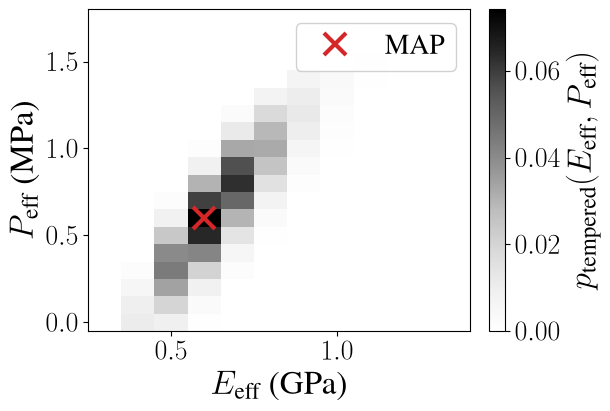

In [4]:
def mass_range(x, p, keep=0.999, pad_cells=3):
    """Smallest set of cells holding `keep` of p, as an (lo, hi) range padded by a
    few cells and clipped to the grid."""
    order = np.argsort(p)[::-1]
    n = min(int(np.searchsorted(np.cumsum(p[order]), keep)) + 1, x.size)
    d = np.median(np.diff(x))
    lo = max(x[order[:n]].min() - pad_cells * d, x.min() - d / 2)
    hi = min(x[order[:n]].max() + pad_cells * d, x.max() + d / 2)
    return lo, hi


def draw_joint(ax):
    """p(E, P) mesh with the MAP marked; returns the mesh for a colorbar."""
    # Cells not scored in every block stay blank rather than reading as zero mass.
    shown = np.where(valid, post, np.nan)
    mesh = ax.pcolormesh(E_gpa, P_mpa, shown.T, shading="nearest", cmap=CMAP,
                         vmin=0.0, vmax=np.nanmax(shown), rasterized=True)
    ax.plot(ep["E_map"] / 1e9, ep["P_map"] / 1e6, "x", color="tab:red", ms=16, mew=3,
            label="MAP")
    ax.set_xlabel(r"$E_\text{eff}$ (GPa)")
    ax.set_ylabel(r"$P_\text{eff}$ (MPa)")
    ax.legend(loc="upper right", framealpha=0.9)
    if ZOOM:
        ax.set_xlim(*mass_range(E_gpa, p_E))
        ax.set_ylim(*mass_range(P_mpa, p_P))
    return mesh


fig, ax = plt.subplots(figsize=(6, 4), constrained_layout=True)
mesh = draw_joint(ax)
cb = fig.colorbar(mesh, ax=ax, location="right")
cb.set_label(r"$p_\text{tempered}(E_\text{eff}, P_\text{eff})$")

fig.savefig(FIG_DIR / f"posterior_EP_2d_{EP_FIELD}.pdf")
plt.show()